In [5]:
import numpy as np
import matplotlib.pyplot as plt
import scienceplots
import seaborn as sns

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


plt.style.use(['science', 'nature','notebook', 'grid'])
plt.rcParams.update({
    #"font.family": "serif",
    "font.size": 14,           # base font size for ticks and labels
    "axes.labelsize": 24,      # y-label size
    "axes.titlesize": 30,      # title
    "xtick.labelsize": 20,
    "ytick.labelsize": 20,
    "legend.fontsize": 14,
  #  "mathtext.fontset": "cm",  # use Computer Modern math
    "axes.linewidth": 1.2,
})

In [6]:

# -----------------------------
# USER EDITS: file lists
# -----------------------------
GP_CSVS = [
  "res_0.25MeV_noise0.01_gp_rbf.h5.csv",
  "res_0.50MeV_noise0.01_gp_rbf.h5.csv",
  "res_1.00MeV_noise0.01_gp_rbf.h5.csv",
  "res_2.00MeV_noise0.01_gp_rbf.h5.csv",
  "res_0.25MeV_noise0.02_gp_rbf.h5.csv",
  "res_0.50MeV_noise0.02_gp_rbf.h5.csv",
  "res_1.00MeV_noise0.02_gp_rbf.h5.csv",
  "res_2.00MeV_noise0.02_gp_rbf.h5.csv",
  "cv0.00_spacing0.5_gp_rbf.h5.csv",
  "cv0.25_spacing0.5_gp_rbf.h5.csv",
  "cv0.50_spacing0.5_gp_rbf.h5.csv",
  "cv0.75_spacing0.5_gp_rbf.h5.csv",
  "cv0.00_spacing1.0_gp_rbf.h5.csv",
  "cv0.25_spacing1.0_gp_rbf.h5.csv",
  "cv0.50_spacing1.0_gp_rbf.h5.csv",
  "cv0.75_spacing1.0_gp_rbf.h5.csv",
]

BNN_CSVS = [
  "res_0.25MeV_noise0.01_bnn_soc.h5.csv",
  "res_0.50MeV_noise0.01_bnn_soc.h5.csv",
  "res_1.00MeV_noise0.01_bnn_soc.h5.csv",
  "res_2.00MeV_noise0.01_bnn_soc.h5.csv",
  "res_0.25MeV_noise0.02_bnn_soc.h5.csv",
  "res_0.50MeV_noise0.02_bnn_soc.h5.csv",
  "res_1.00MeV_noise0.02_bnn_soc.h5.csv",
  "res_2.00MeV_noise0.02_bnn_soc.h5.csv",
  "cv0.00_spacing0.5_bnn_soc.h5.csv",
  "cv0.25_spacing0.5_bnn_soc.h5.csv",
  "cv0.50_spacing0.5_bnn_soc.h5.csv",
  "cv0.75_spacing0.5_bnn_soc.h5.csv",
  "cv0.00_spacing1.0_bnn_soc.h5.csv",
  "cv0.25_spacing1.0_bnn_soc.h5.csv",
  "cv0.50_spacing1.0_bnn_soc.h5.csv",
  "cv0.75_spacing1.0_bnn_soc.h5.csv",
]

TITLES = [
    r"$\kappa=0.00$, $\Delta E=0.25 MeV$, $\eta=0.01$",
    r"$\kappa=0.00$, $\Delta E=0.50 MeV$, $\eta=0.01$",
    r"$\kappa=0.00$, $\Delta E=1.00 MeV$, $\eta=0.01$",
    r"$\kappa=0.00$, $\Delta E=2.00 MeV$, $\eta=0.01$",
    r"$\kappa=0.00$, $\Delta E=0.25 MeV$, $\eta=0.02$",
    r"$\kappa=0.00$, $\Delta E=0.50 MeV$, $\eta=0.02$",
    r"$\kappa=0.00$, $\Delta E=1.00 MeV$, $\eta=0.02$",
    r"$\kappa=0.00$, $\Delta E=2.00 MeV$, $\eta=0.02$",
    r"$\kappa=0.00$, $\Delta E=0.5 MeV$, $\eta=0.01$",
    r"$\kappa=0.25$, $\Delta E=0.5 MeV$, $\eta=0.01$",
    r"$\kappa=0.50$, $\Delta E=0.5 MeV$, $\eta=0.01$",
    r"$\kappa=0.75$, $\Delta E=0.5 MeV$, $\eta=0.01$",
    r"$\kappa=0.00$, $\Delta E=1.0 MeV$, $\eta=0.01$",
    r"$\kappa=0.25$, $\Delta E=1.0 MeV$, $\eta=0.01$",
    r"$\kappa=0.50$, $\Delta E=1.0 MeV$, $\eta=0.01$",
    r"$\kappa=0.75$, $\Delta E=1.0 MeV$, $\eta=0.01$",
]

# base directories (edit if needed)
GP_DIR  = "/mnt/home/philipaa/scratch/barrier-paper-results"
BNN_DIR = "/mnt/home/philipaa/scratch/barrier-paper-results"


In [7]:
# plot settings
CUTOFF = 20000
WHICH  = "barrier"   # "barrier" or "sigma"
ALPHA  = 0.75
LW     = 1.6


KIND = "barrier"          # "barrier" or "sigma"
NORMALIZE = True          # normalized by hw_true * R0_true^2 (like your script)
CUTOFF_RMSE = 200000
HT_GATE = 1000.0           # |ht_true - ht_pred| < 100
GP_STRIDE = 10            # GP index = BNN index * 10

# colors (consistent with your earlier aesthetic)
GP_COLOR  = "tab:blue"
BNN_COLOR = "tab:green"



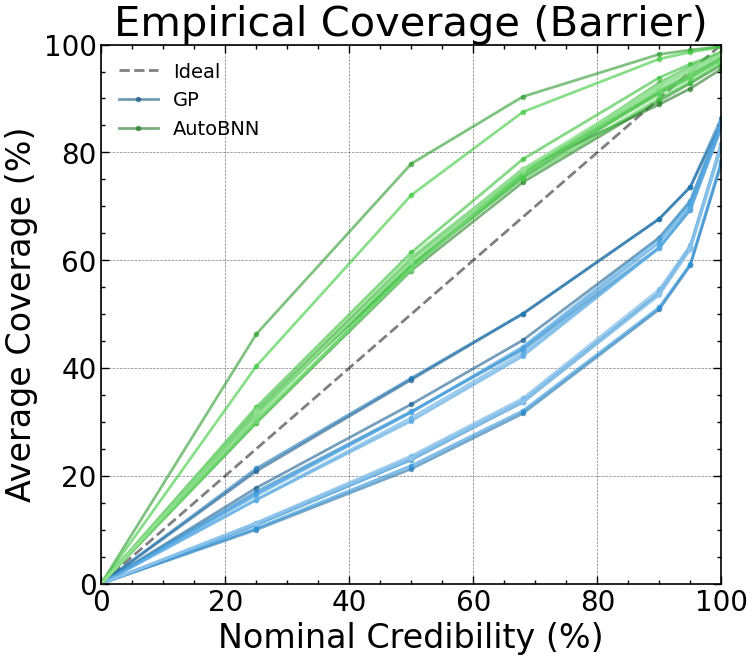

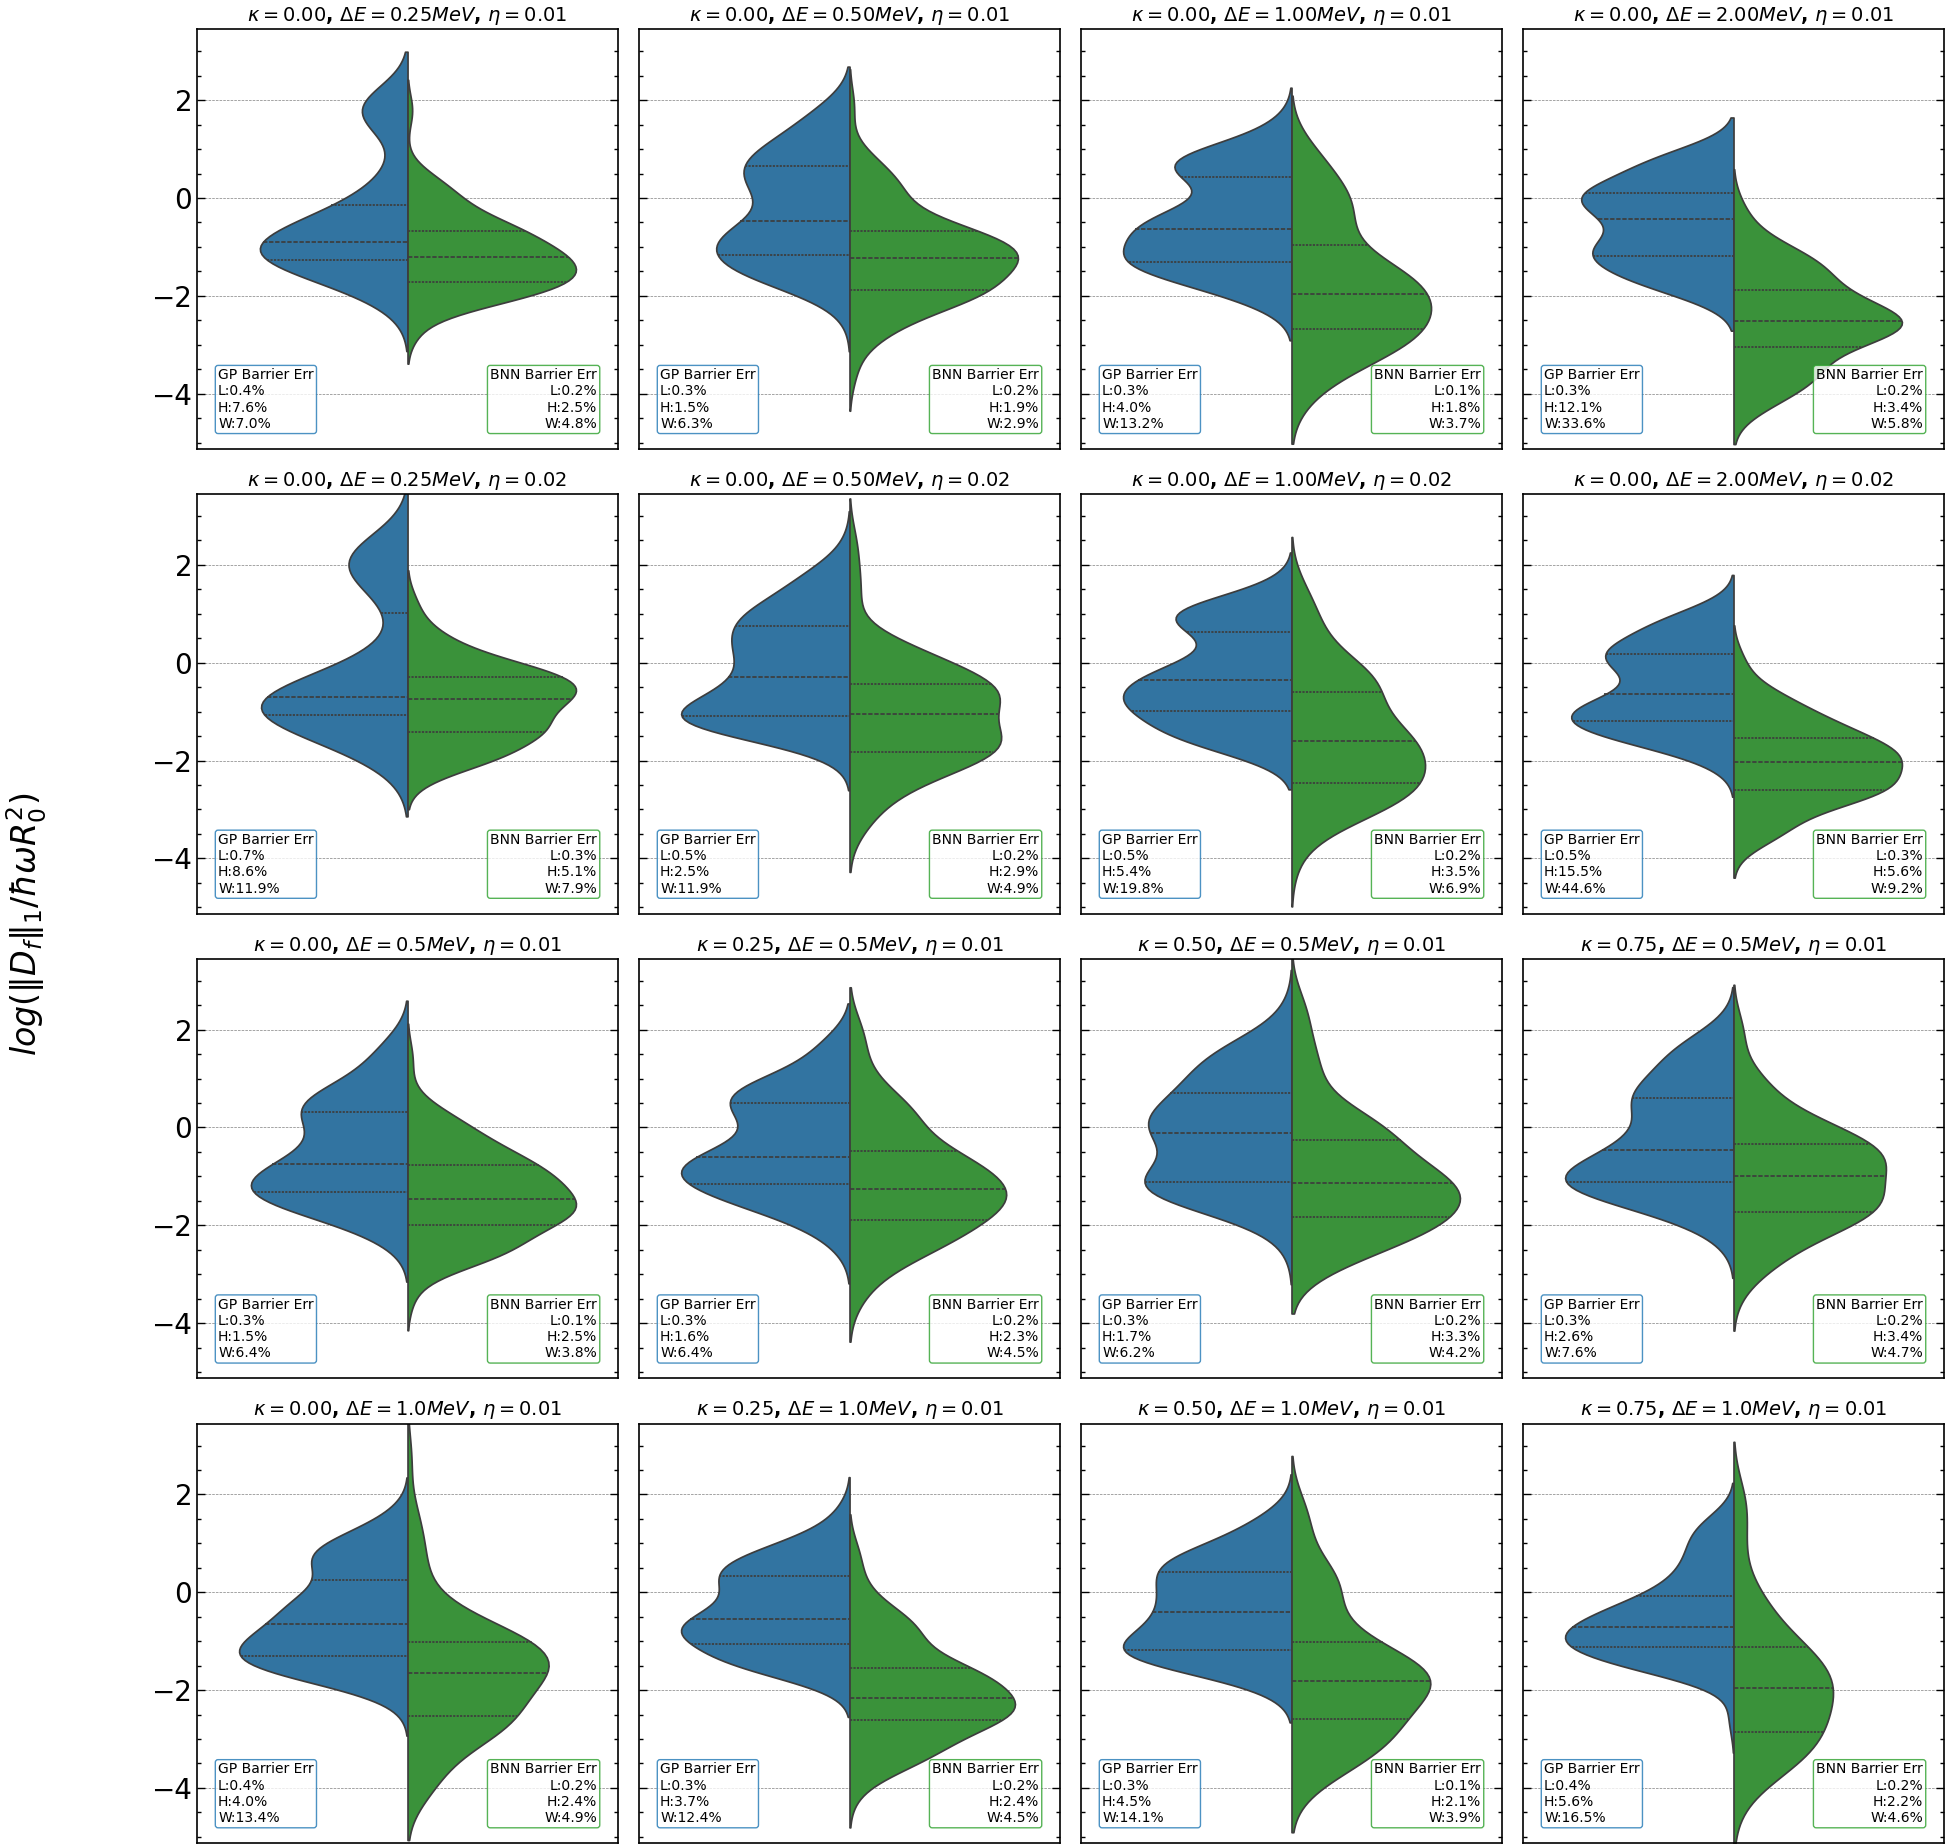

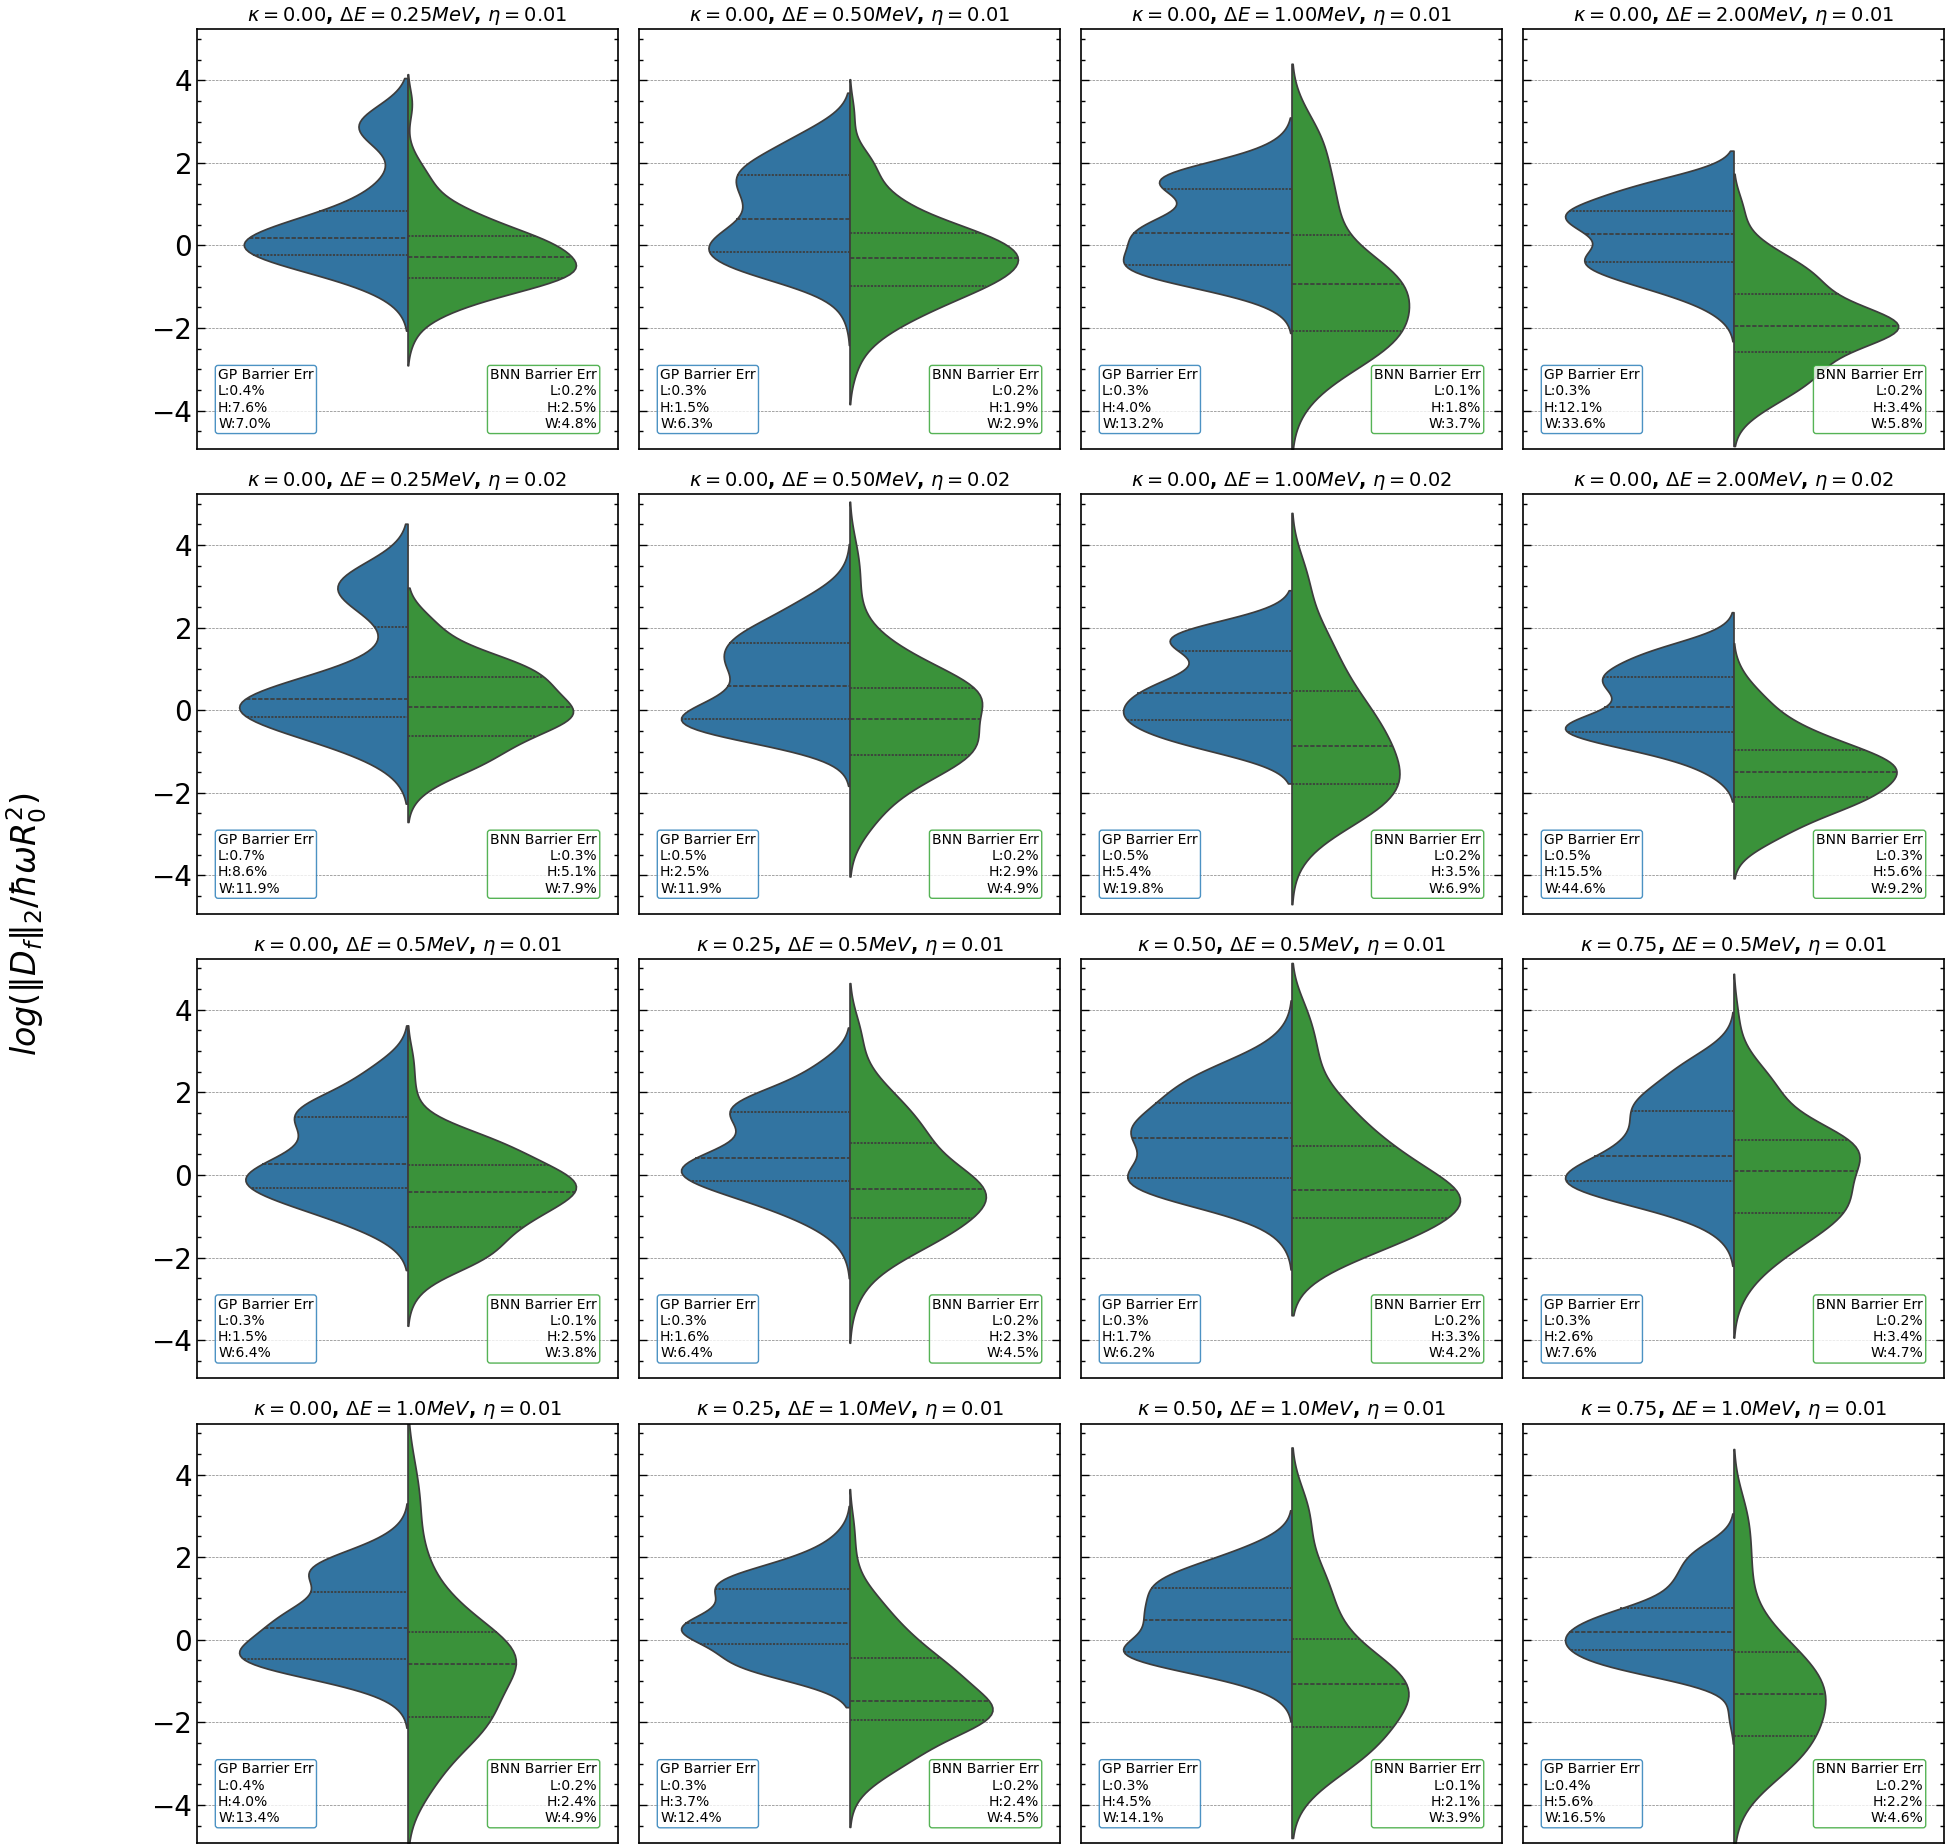

In [16]:
import colorsys
from matplotlib.colors import to_rgb

# --- CONFIGURATION ---
BASE_DIR = "/mnt/home/philipaa/scratch/barrier-paper-results"
SAVE_DIR = "../plots"

SETTINGS = {
    "cutoff_rmse": 20000,
    "ht_gate": 1000.0,
    "gp_stride": 10,
    "normalize": True,
    "kind": "barrier" 
}

# --- CORE UTILITIES ---

def get_shades(base_color, n, lightness=(0.3, 0.75)):
    r, g, b = to_rgb(base_color)
    h, l, s = colorsys.rgb_to_hls(r, g, b)
    ls = np.linspace(lightness[0], lightness[1], n)
    return [colorsys.hls_to_rgb(h, float(l_val), s) for l_val in ls]

def load_processed_df(filename, is_bnn=False):
    path = os.path.join(BASE_DIR, filename)
    if not os.path.exists(path):
        print(f"File not found: {path}")
        return pd.DataFrame()
    
    df = pd.read_csv(path)
    
    # 1. Numeric conversion
    cols_to_fix = [c for c in df.columns if any(x in c for x in ['MAE', 'resid', 'true', 'pred', 'RMSE', 'cov', 'index'])]
    for col in cols_to_fix:
        df[col] = pd.to_numeric(df[col], errors='coerce')

    # 2. Universal RMSE Filter
    if "barrier_RMSE" in df.columns:
        df = df[df["barrier_RMSE"] <= SETTINGS["cutoff_rmse"]]

    # 3. BNN Convergence Gate
    if is_bnn and "barrier_peak_ht_true" in df.columns:
        gate = (df["barrier_peak_ht_true"] - df["barrier_peak_ht_pred"]).abs() < SETTINGS["ht_gate"]
        df = df[gate]
    
    # 4. Normalization
    if SETTINGS["normalize"] and "hw_true" in df.columns:
        norm = df["hw_true"] * (df["R0_true"] ** 2)
        norm = norm.replace(0, np.nan)
        for target in ["barrier_MAE", 'barrier_RMSE']:
            if target in df.columns:
                df[target] = df[target] / norm
                
    return df.dropna(subset=['index'])

# --- PLOTTING FUNCTIONS ---

def plot_coverage_curves(gp_files, bnn_files):
    fig, ax = plt.subplots(figsize=(8, 7))
    ax.plot([0, 100], [0, 100], 'k--', alpha=0.5, label="Ideal")
    
    colors_gp = get_shades("tab:blue", len(gp_files))
    colors_bnn = get_shades("tab:green", len(bnn_files))

    for files, colors, label_prefix in [(gp_files, colors_gp, "GP"), (bnn_files, colors_bnn, "AutoBNN")]:
        for i, (fname, col) in enumerate(zip(files, colors)):
            df = load_processed_df(fname, is_bnn=("bnn" in fname))
            if df.empty: continue
            
            prefix = f"{SETTINGS['kind']}_emp_cov_"
            cov_cols = [c for c in df.columns if c.startswith(prefix)]
            
            # Extract numerical level from column name and sort numerically
            col_map = {c: int(c.split('_')[-1]) for c in cov_cols}
            sorted_cols = sorted(cov_cols, key=lambda x: col_map[x])
            
            levels = [col_map[c] for c in sorted_cols]
            means = [df[c].mean() * 100 for c in sorted_cols] # Convert to %
            
            ax.plot(levels, means, color=col, alpha=0.6, marker="o",
                    label=label_prefix if i == 0 else None)

    ax.set(xlabel="Nominal Credibility (%)", ylabel="Average Coverage (%)", 
           title=f"Empirical Coverage ({SETTINGS['kind'].capitalize()})")
    ax.set_xlim(0, 100); ax.set_ylim(0, 100)
    ax.legend(frameon=False)
    plt.savefig(f"{SAVE_DIR}/Coverage.png", dpi=300)

def plot_violin_grid(gp_files, bnn_files, titles, metric_type="MAE"):
    # --- 1. PRE-CALCULATE GLOBAL Y-LIMITS ---
    all_log_vals = []
    processed_pairs = []
    target_err = f"{SETTINGS['kind']}_{metric_type}"

    for gp_f, bnn_f in zip(gp_files, bnn_files):
        df_gp = load_processed_df(gp_f, is_bnn=False)
        df_bnn = load_processed_df(bnn_f, is_bnn=True)
        
        if not df_gp.empty and not df_bnn.empty:
            df_bnn['match_idx'] = (df_bnn['index'] * SETTINGS['gp_stride']).astype(int)
            df_gp['index_int'] = df_gp['index'].astype(int)
            matched = pd.merge(df_bnn, df_gp, left_on='match_idx', right_on='index_int', suffixes=('_bnn', '_gp'))
            
            if not matched.empty:
                v_gp = np.log(matched[f"{target_err}_gp"].astype(float))
                v_bnn = np.log(matched[f"{target_err}_bnn"].astype(float))
                # Filter out infinities from log(0) before calculating limits
                valid_gp = v_gp[np.isfinite(v_gp)]
                valid_bnn = v_bnn[np.isfinite(v_bnn)]
                all_log_vals.extend(valid_gp.tolist())
                all_log_vals.extend(valid_bnn.tolist())
                processed_pairs.append((matched, df_gp, df_bnn))
            else:
                processed_pairs.append(None)
        else:
            processed_pairs.append(None)

    # Global bounds logic
    if all_log_vals:
        y_min, y_max = min(all_log_vals), max(all_log_vals)
        y_buffer = (y_max - y_min) * 0.1
        global_ylim = (y_min - y_buffer, y_max + y_buffer)
    else:
        global_ylim = (-5, 5)

    # --- 2. PLOTTING ---
    fig, axes = plt.subplots(4, 4, figsize=(20, 20), sharey=True)
    axes_flat = axes.flatten()

    for i, pair_data in enumerate(processed_pairs):
        ax = axes_flat[i]
        if pair_data is None:
            ax.text(0.5, 0.5, "Insufficient Data", ha='center'); ax.set_axis_off(); continue
            
        matched, df_gp_raw, df_bnn_raw = pair_data

        gp_v = np.log(matched[f"{target_err}_gp"].astype(float))
        bnn_v = np.log(matched[f"{target_err}_bnn"].astype(float))
        
        # CORRECTED DATA CONSTRUCTION
        combined_vals = np.concatenate([gp_v, bnn_v])
        plot_df = pd.DataFrame({
            "val": combined_vals,
            "model": ["GP"]*len(gp_v) + ["AutoBNN"]*len(bnn_v),
            "x": [0] * len(combined_vals)  # Length of the combined array
        })

        sns.violinplot(data=plot_df, x="x", y="val", hue="model", split=True,
                       hue_order=["GP", "AutoBNN"],
                       palette={"GP": "tab:blue", "AutoBNN": "tab:green"}, 
                       ax=ax, inner="quartile", density_norm="area", common_norm=True)

        # --- 3. PERCENT ERROR ANNOTATIONS ---
        for name, m_df, color, side in [('GP', df_gp_raw, 'tab:blue', 0.05), ('BNN', df_bnn_raw, 'tab:green', 0.95)]:
            def get_mape(suffix):
                if suffix == "fwhm":
                    col_resid = f"barrier_fwhm_resid"
                    col_true = f"barrier_fwhm_true"
                else:
                    col_resid = f"barrier_peak_{suffix}_resid"
                    col_true = f"barrier_peak_{suffix}_true"
                if col_resid in m_df.columns and col_true in m_df.columns:
                    resid = m_df[col_resid].abs()
                    true_val = m_df[col_true].abs()
                    mask = (true_val > 1e-9) # Avoid div by zero
                    return (resid[mask] / true_val[mask]).mean() * 100
                return np.nan

            p_loc = get_mape("loc")
            p_ht  = get_mape("ht")
            p_fw  = get_mape("fwhm")
            
            txt = f"{name} Barrier Err\nL:{p_loc:.1f}%\nH:{p_ht:.1f}%\nW:{p_fw:.1f}%"
            ax.text(side, 0.05, txt, transform=ax.transAxes, color='black', fontsize=10,
                    ha=('left' if side < 0.5 else 'right'), 
                    bbox=dict(facecolor='white', alpha=0.8, edgecolor=color, boxstyle="round,pad=0.2"))

        ax.set_title(titles[i], fontsize=14, fontweight='bold')
        ax.set_ylim(global_ylim)
        ax.set(xlabel="", ylabel="", xticks=[])
        if ax.get_legend(): ax.get_legend().remove()
        
        ylabel = r"$log( \|D_f\|_1 / \hbar \omega R_0 ^2 )$" if metric_type == "MAE" else r"$log (\|D_f\|_2 / \hbar \omega R_0 ^2) $"

    fig.supylabel(ylabel, fontsize=24, fontweight='bold') # f"log({SETTINGS['kind'].capitalize()}_{metric_type})"
    plt.tight_layout(rect=[0.05, 0.03, 1, 0.97])
    plt.savefig(f"{SAVE_DIR}/{metric_type}_Grid.png", dpi=300)

# --- EXECUTION ---
# Ensure your GP_CSVS, BNN_CSVS, and titles lists are defined before calling
plot_coverage_curves(GP_CSVS, BNN_CSVS)
plot_violin_grid(GP_CSVS, BNN_CSVS, TITLES, metric_type="MAE")
plot_violin_grid(GP_CSVS, BNN_CSVS, TITLES, metric_type="RMSE")
plt.show()